<!-- colab-badge -->
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RemusTeodorescu/DL-for-Engineers-Public-Course/blob/main/miniprojects/MP8.2A/MP8.2A_01_data_and_physics.ipynb)

*Open this notebook in Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU). Its first code cell fetches the library files from the public course repository.*

<!-- course-header v3 -->

**Deep Learning for Engineering** · MSc, Aalborg University · 2026

Developed by **Remus Teodorescu** (ret@et.aau.dk), with support from Research Assistant **Noman Khan** (nomank@energy.aau.dk).

*Reference texts — read for the theory. Used as an **inspirational source** for this course, not as a source of its code:*

- Liu, *PINN with Python*, 2025.
- Raissi, Perdikaris & Karniadakis, *Physics-informed neural networks*, J. Comput. Phys. 378 (2019) 686–707.
- Prince, *Understanding Deep Learning*, MIT Press 2023.

Every notebook in this course has been **written and rewritten by the authors named above**. The code, the problems, the data and the exposition are **original to this course** and are not derived from any publisher's code listings or companion notebooks. Where notation matches a textbook's it is the standard notation of the field, and where an idea is a named author's it is cited as theirs in the text.

See `docs/PROVENANCE.md` for what each reference is cited for, set by set.

---

# MP8.2A · Thermal Cycling with Natural Convection
## 01 · The Data and the Physics

*Mini project of the course **Deep Learning for Engineering**, Part 2. Five notebooks, run in order:*

00 The Problem → **01 The Data and the Physics** → 02 The Reference Model and the Ground Truth → 03 The Physics-Informed Network → 04 The Report

*Notebooks 00 to 02 are given and solved: read them, run them, and use what they build. Notebooks 03 and 04 are yours.*

In [1]:
# files-cell (mini project) ----------------------------------------------------
# The library files must sit beside the notebook. Locally they already do. On
# Google Colab they are fetched from the public course repository on every
# run, so a file left over from an earlier session cannot shadow it.
import os, sys, urllib.request
EXERCISE = (['course_core.py', 'pinn_core.py', 'heatsink.py'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/exercises/Ex08-heatsink-cooling/")
PROJECT = (['mp82a.py', 'MP8.2A_truth.npz'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/miniprojects/MP8.2A/")
ON_COLAB = "google.colab" in sys.modules
for files, url in (EXERCISE, PROJECT):
    for f in files:
        if ON_COLAB or not os.path.exists(f):
            if not ON_COLAB and os.path.exists(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f)):
                import shutil; shutil.copy(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f), f)
            else:
                urllib.request.urlretrieve(url + f, f)
            print("fetched", f)
for _m in ['course_core', 'pinn_core', 'heatsink', 'mp82a']:
    sys.modules.pop(_m, None)
print("files ready")

files ready


In [2]:
# --- setup ---------------------------------------------------------------
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import course_core as cc
import heatsink as hs
import mp82a as mp
torch.set_default_dtype(torch.float64)                   # a second derivative of a network needs double precision
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # the GPU, when the runtime has one
cc.keep_outputs("MP8.2A_outputs")                            # results kept between the notebooks (Google Drive on Colab)
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cu130


## 1 · What the network takes and returns

The network is a function of four inputs and returns one number:

$$(x,\ z,\ t,\ P)\ \longmapsto\ \theta(x, z, t; P)$$

the rise above the air at a point of the base plate, at an instant, for a module power. The power is an **input**, like the coordinates: one training covers every power from 100 to 200 W, and a new power is answered by evaluating the network, not by training again.

Networks train best when their inputs and output are of order one. The cell below prints the scales of this problem, which Ex08 used too.

In [3]:
# The scales: inputs and output of order one
print(f"X = x / W,     W   = {hs.W_BASE*1e3:.0f} mm")
print(f"Z = z / t_b,   t_b = {hs.T_BASE*1e3:.0f} mm")
print(f"θ̂ = θ / Θ,     Θ   = q_mean / h_eff(0) = {hs.THETA:.2f} K   (the fin-side rise of a 1-D hand calculation at 150 W)")
print(f"diffusion time through the thickness  t_b²/α = {hs.T_BASE**2/hs.ALPHA:.2f} s")
print(f"aspect ratio ε = t_b / W = {hs.EPS:.2f};   Biot number at no rise  Bi = h_eff t_b / k = {hs.BI:.4f}")
print(f"window {mp.T_END:.0f} s; power {mp.P_MIN:.0f}-{mp.P_MAX:.0f} W")

X = x / W,     W   = 100 mm
Z = z / t_b,   t_b = 10 mm
θ̂ = θ / Θ,     Θ   = q_mean / h_eff(0) = 46.57 K   (the fin-side rise of a 1-D hand calculation at 150 W)
diffusion time through the thickness  t_b²/α = 1.46 s
aspect ratio ε = t_b / W = 0.10;   Biot number at no rise  Bi = h_eff t_b / k = 0.0193
window 600 s; power 100-200 W


## 2 · The physics the network is trained with

In the scaled variables the heat equation and its conditions read

$$\frac{t_b^2}{\alpha}\,\frac{\partial \hat\theta}{\partial t} = \varepsilon^2\,\frac{\partial^2 \hat\theta}{\partial X^2} + \frac{\partial^2 \hat\theta}{\partial Z^2}$$

$$\frac{\partial \hat\theta}{\partial Z} = Bi\; g(X)\,\frac{P}{P_0}\,s(t) \ \ \text{at } Z = 1, \qquad
\frac{\partial \hat\theta}{\partial Z} = \frac{h_\mathrm{eff}(\Theta\hat\theta)\,t_b}{k}\,\hat\theta \ \ \text{at } Z = 0, \qquad
\frac{\partial \hat\theta}{\partial X} = 0 \ \ \text{at } X = 0, 1, \qquad \hat\theta = 0 \ \ \text{at } t = 0$$

with $g(X) = q''/q_\mathrm{mean}$ on the footprint (3.33) and 0 elsewhere. Each line becomes a term of the loss: the squared residual of the equation at points inside the plate, and of each condition at points on its face.

| loss term | where it is evaluated | what it enforces |
|---|---|---|
| $\mathcal{L}_\mathrm{PDE}$ | interior points $(X, Z, t, P)$ | the heat equation: conduction and storage |
| $\mathcal{L}_\mathrm{module}$ | points on $Z = 1$ | the module's heat enters on the footprint, nothing elsewhere |
| $\mathcal{L}_\mathrm{fins}$ | points on $Z = 0$ | the nonlinear fin condition, with $h_\mathrm{eff}$ at the network's own rise |
| $\mathcal{L}_\mathrm{ends}$ | points on $X = 0, 1$ | insulated ends |
| $\mathcal{L}_\mathrm{start}$ | points at $t = 0$ | the sink starts at the air's temperature |

**What can be built in rather than trained.** Ex08 showed that a condition built into the network's form holds exactly and leaves the training less to do. Here: the insulated ends hold for any weights if the network sees $X$ only through $\cos(\pi X)$, whose slope is zero at both ends; the start holds if the output is written so that it vanishes at $t = 0$. Whether and how you build these in is one of your choices in notebook 03.

**The energy balance, at every instant.** Integrated over the plate, the heat equation says that the heat stored changes at the rate the module puts heat in minus the rate the fins take it out:

$$\frac{t_b^2}{\alpha}\,\frac{d\langle\hat\theta\rangle}{dt} = Bi\,\frac{P}{P_0}\,s(t) - \left\langle \frac{h_\mathrm{eff}\,t_b}{k}\,\hat\theta \right\rangle_{Z=0}$$

where $\langle\cdot\rangle$ is the mean over the plate (left) or over the fin side (right). It follows from the equation and the two face conditions, so a network that satisfied them exactly would satisfy it too. **But no network satisfies them exactly, and over 600 s that matters**: a residual of one part in a thousand in the equation, integrated over a hundred seconds, becomes a drift of the stored heat of several kelvin. Ex08 met the same problem in its steady sink, and its cure was this balance as a loss term. In time it is needed more, not less. Notebook 03 gives it as an optional term, `balance_loss`; whether and how much to weight it is your choice.

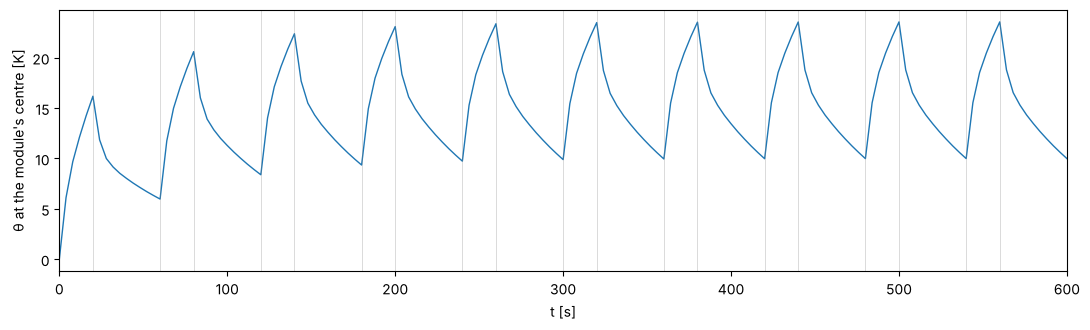

peaks  : [16.18 20.6  22.38 23.09 23.37 23.48 23.53 23.55 23.55 23.56]
troughs: [5.97 8.38 9.35 9.73 9.89 9.95 9.97 9.98 9.99 9.99]


In [4]:
# What the network must represent: the centre's rise at 150 W, from the reference model
ref = mp.reference(150.0)                                # Crank-Nicolson on the engineering grid (notebook 02)
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(ref["t"], ref["centre"], lw=1)
for s in mp.SWITCHES:
    ax.axvline(s, color="grey", lw=0.4, alpha=0.5)
ax.set_xlabel("t [s]"); ax.set_ylabel("θ at the module's centre [K]"); ax.set_xlim(0, mp.T_END)
plt.tight_layout(); plt.show()
print("peaks  :", np.round(ref["peaks"], 2))
print("troughs:", np.round(ref["troughs"], 2))

**What you should see.** A saw-tooth that climbs for about six cycles and then repeats: peaks 16.2, 20.6, 22.4 ... 23.6 K and troughs 6.0, 8.4, 9.4 ... 10.0 K at 150 W, from the reference model (notebook 02 shows it is within 0.2 K of the ground truth). The slope changes abruptly at every grey line, a switch. A network that is smooth in $t$ - a plain multilayer perceptron of $t$ - rounds those corners, and the rounding is largest exactly at the peaks it is scored on. Ways around it that you may consider in notebook 03: give the network inputs that carry the switching (functions of $t$ built from $s(t)$), train cycle by cycle, or build a simpler model of the history into the network and let it learn the correction.

## 3 · The training points

A physics-informed network needs no solution to train on: it needs **points** at which to evaluate the residuals. `mp82a.py` provides samplers for the three sets. Two choices are made in them, each a parameter you may change:

* **in time** (`near`), a quarter of the instants fall in the few seconds after a switch (exponentially distributed, mean 4 s), where the field changes fastest; the rest are uniform over the 600 s;
* **on the module face** (`edges`), a tenth of the points fall within 2.5 mm of the footprint's two edges, where the flux steps from zero to 50 kW/m².

Both concentrations have a cost worth knowing. A smooth network cannot follow a step in the flux exactly, so points right at the footprint's edges and right after a switch keep a residual that no training removes. Put too many there and that residual dominates the loss and hides everything else; put none and the network has no reason to be sharp where the field is. The defaults are a compromise; a uniform face (`edges=0`) is a reasonable choice too.

The power is drawn uniformly from 100 to 200 W. The three **test powers, 115, 165 and 195 W**, are inside the range, but no point is placed at them on purpose: the network is scored where it was not fitted.

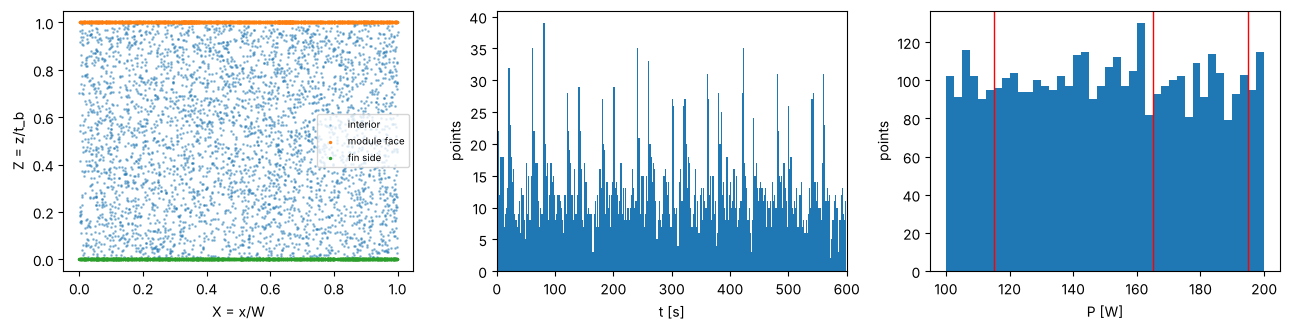

In [5]:
# The three sets of training points
X, Z, t, Pw = mp.sample_interior(4000)                    # inside the plate
Xt, tt, Pt = mp.sample_top(1500)                          # on the module face
Xb, tb, Pb = mp.sample_bottom(1500)                       # on the fin side
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].scatter(X, Z, s=1, alpha=0.4, label="interior")
ax[0].scatter(Xt, np.ones_like(Xt), s=2, label="module face")
ax[0].scatter(Xb, np.zeros_like(Xb), s=2, label="fin side")
ax[0].set_xlabel("X = x/W"); ax[0].set_ylabel("Z = z/t_b"); ax[0].legend(fontsize=7, loc="center right")
ax[1].hist(t, bins=300); ax[1].set_xlabel("t [s]"); ax[1].set_ylabel("points"); ax[1].set_xlim(0, mp.T_END)
ax[2].hist(Pw, bins=40); ax[2].set_xlabel("P [W]"); ax[2].set_ylabel("points")
for p in mp.P_TEST:
    ax[2].axvline(p, color="red", lw=1)
plt.tight_layout(); plt.show()

**What you should see.** Left, the plate with its points, slightly denser on the module face round the footprint's edges at $X$ = 0.35 and 0.65. Middle, twenty spikes, one after each switch, over a uniform floor. Right, a flat distribution of powers with the three test powers in red.

## 4 · Measured data, if your design wants some

The physics alone determines the answer, so no measurement is needed. Some designs nevertheless train faster or more robustly with a few data points added to the loss - a **hybrid** network. For that, `mp.thermocouple(P)` returns the record of Ex08's thermocouple, glued to the module face at $x$ = 80 mm, every 2 s with 0.05 K of noise, computed from the ground truth. If you use it, use it at powers other than the test powers, and say in the report what it changed.

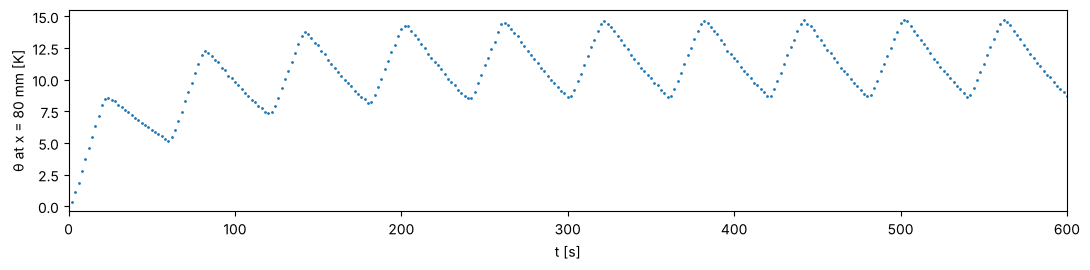

300 readings, noise 0.05 K


In [6]:
# A thermocouple record at 130 W, with its noise
t_tc, th_tc = mp.thermocouple(130.0)
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(t_tc, th_tc, ".", ms=2)
ax.set_xlabel("t [s]"); ax.set_ylabel("θ at x = 80 mm [K]"); ax.set_xlim(0, mp.T_END)
plt.tight_layout(); plt.show()
print(f"{len(t_tc)} readings, noise {hs.NOISE_K} K")

**What you should see.** 300 readings: the same saw-tooth as the centre's, smaller (the thermocouple is 15 mm beyond the footprint's edge) and later, with the noise visible as a slight scatter.